In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import os

# Caminho para a pasta onde os dados foram extraídos
DATASET_DIR = "../data/doenca" 

BATCH_SIZE = 32
# A MobileNetV2 espera imagens quadradas de 224x224
IMG_SIZE = (224, 224) 

print("Carregando conjunto de TREINO:")
treino_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "treino"),
    shuffle=True, # Embaralha para o modelo não viciar na ordem
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
)

print("\nCarregando conjunto de VALIDAÇÃO:")
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "validacao"),
    shuffle=False, # Não precisamos embaralhar validação
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
)

print("\nCarregando conjunto de TESTE:")
teste_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "teste"),
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
)

class_names = treino_ds.class_names
print(f"\nClasses detectadas: {class_names}")

# Otimização de I/O focada em poupar memória RAM
AUTOTUNE = tf.data.AUTOTUNE
# O .cache() foi removido. O prefetch() já é suficiente para manter o fluxo contínuo!
treino_ds = treino_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
teste_ds = teste_ds.prefetch(buffer_size=AUTOTUNE)

Carregando conjunto de TREINO:
Found 1813 files belonging to 2 classes.

Carregando conjunto de VALIDAÇÃO:
Found 389 files belonging to 2 classes.

Carregando conjunto de TESTE:
Found 389 files belonging to 2 classes.

Classes detectadas: ['pinta_preta', 'saudavel']


In [2]:
# 1. Camada de Aumento de Dados (Data Augmentation)
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2),
    ],
    name="data_augmentation",
)

# 2. Carregando a MobileNetV2 pré-treinada
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False, # Remove a camada final original (que classificava 1000 objetos genéricos)
    weights='imagenet'
)

# Congelando os pesos da base para aproveitar o conhecimento prévio
base_model.trainable = False

# 3. Montando o modelo final
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)

# A MobileNetV2 exige que os pixels (0 a 255) sejam normalizados entre -1 e 1
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
x = preprocess_input(x)

# Passando as imagens pela base congelada
x = base_model(x, training=False)

# Achata as características encontradas
x = layers.GlobalAveragePooling2D()(x)

# Dropout de 20% para forçar a rede a não decorar os dados (evita overfitting)
x = layers.Dropout(0.2)(x) 

# Camada de Saída: 1 único neurônio com Sigmoid (0 = Pinta Preta, 1 = Saudável)
outputs = layers.Dense(1, activation='sigmoid')(x)

model = keras.Model(inputs, outputs)

# Compilando o modelo
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

# Exibe o resumo da arquitetura
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Iniciando o treinamento da Baseline de Doenças...
Epoch 1/20


c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


57/57 ━━━━━━━━━━━━━━━━━━━━ 33s 530ms/step - accuracy: 0.7959 - loss: 0.4525 - val_accuracy: 0.9280 - val_loss: 0.1962
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 449ms/step - accuracy: 0.9294 - loss: 0.2170 - val_accuracy: 0.9589 - val_loss: 0.1222
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 453ms/step - accuracy: 0.9443 - loss: 0.1604 - val_accuracy: 0.9794 - val_loss: 0.0947
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 454ms/step - accuracy: 0.9515 - loss: 0.1405 - val_accuracy: 0.9846 - val_loss: 0.0805
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 456ms/step - accuracy: 0.9570 - loss: 0.1239 - val_accuracy: 0.9820 - val_loss: 0.0730
Epoch 6/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 464ms/step - accuracy: 0.9575 - loss: 0.1191 - val_accuracy: 0.9846 - val_loss: 0.0623
Epoch 7/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 456ms/step - accuracy: 0.9669 - loss: 0.1019 - val_accuracy: 0.9846 - val_loss: 0.0613
Epoch 8/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 452ms/step - accuracy: 0.9658 - loss: 0.1040 - val_accuracy: 0.989

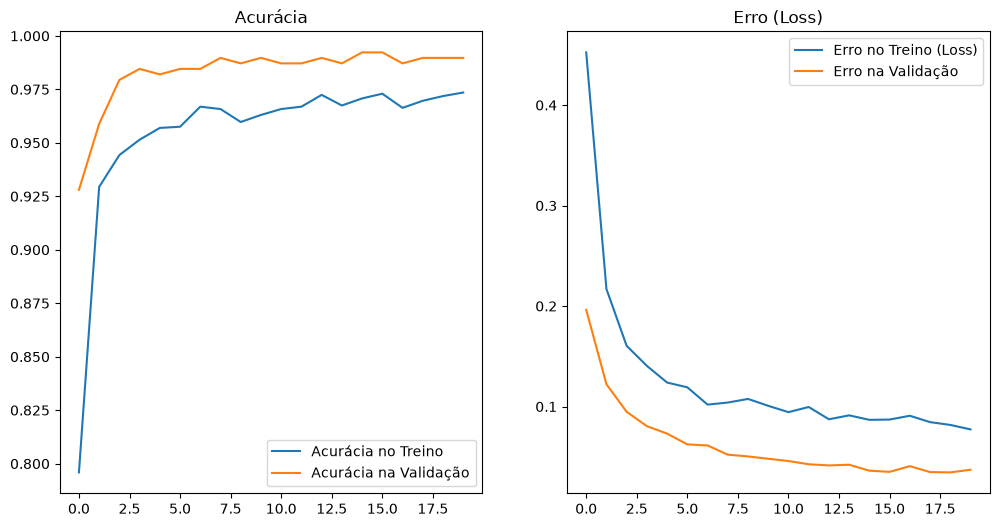

In [3]:
# Callbacks para otimizar o treinamento
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', # Fica de olho no erro da validação
        patience=5,         # Se não melhorar por 5 épocas seguidas, ele para
        restore_best_weights=True # Garante que vai salvar a melhor versão, não a última
    )
]

EPOCHS = 20 # Número máximo de vezes que ele vai ver o dataset inteiro

print("Iniciando o treinamento da Baseline de Doenças...")
history = model.fit(
    treino_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Plotando os gráficos de aprendizado
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Acurácia no Treino')
plt.plot(epochs_range, val_acc, label='Acurácia na Validação')
plt.legend(loc='lower right')
plt.title('Acurácia')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Erro no Treino (Loss)')
plt.plot(epochs_range, val_loss, label='Erro na Validação')
plt.legend(loc='upper right')
plt.title('Erro (Loss)')
plt.show()

In [4]:
# Salvando o modelo treinado localmente
caminho_modelo = "baseline_pinta_preta.keras"
model.save(caminho_modelo)
print(f"Modelo salvo com sucesso em: {caminho_modelo}")

# Caso precise carregar depois sem ter que treinar tudo de novo:
# model = keras.models.load_model(caminho_modelo)

Modelo salvo com sucesso em: baseline_pinta_preta.keras


In [5]:
print("\nAvaliando modelo no Conjunto de Teste (Dados Inéditos)...")
test_loss, test_acc = model.evaluate(teste_ds)
print(f"Acurácia real no Teste: {test_acc:.4f}")
print(f"Erro (Loss) no Teste: {test_loss:.4f}")


Avaliando modelo no Conjunto de Teste (Dados Inéditos)...
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 467ms/step - accuracy: 0.9743 - loss: 0.0667
Acurácia real no Teste: 0.9743
Erro (Loss) no Teste: 0.0667



--- Relatório de Classificação ---
              precision    recall  f1-score   support

 pinta_preta       0.99      0.95      0.97       150
    saudavel       0.97      0.99      0.98       239

    accuracy                           0.97       389
   macro avg       0.98      0.97      0.97       389
weighted avg       0.97      0.97      0.97       389



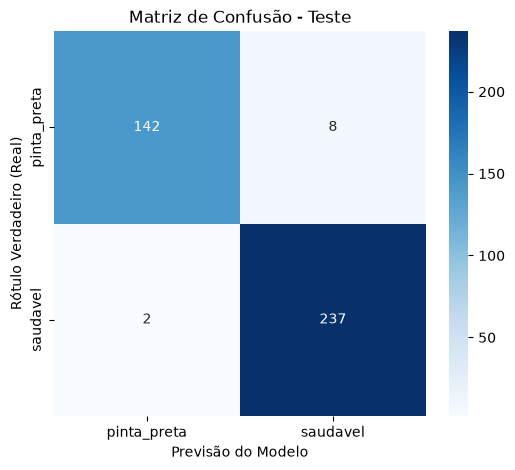

In [12]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Extraindo rótulos reais e previsões lote por lote para poupar RAM
y_true = []
y_pred_probs = []

for images, labels in teste_ds:
    y_true.extend(labels.numpy())
    preds = model.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
# Como a saída é Sigmoid (1 neurônio), consideramos > 0.5 como a classe 1
y_pred = (np.array(y_pred_probs) > 0.5).astype(int)

# CORREÇÃO: Definindo as classes manualmente já que o prefetch removeu o metadado
classes = ['pinta_preta', 'saudavel']

print("\n--- Relatório de Classificação ---")
print(classification_report(y_true, y_pred, target_names=classes))

# Plotando a Matriz de Confusão
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Matriz de Confusão - Teste')
plt.ylabel('Rótulo Verdadeiro (Real)')
plt.xlabel('Previsão do Modelo')
plt.show()

C:\Users\joaom\AppData\Local\Temp\ipykernel_14580\1086333584.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  classe_prevista = classes[int(preds[i] > 0.5)]


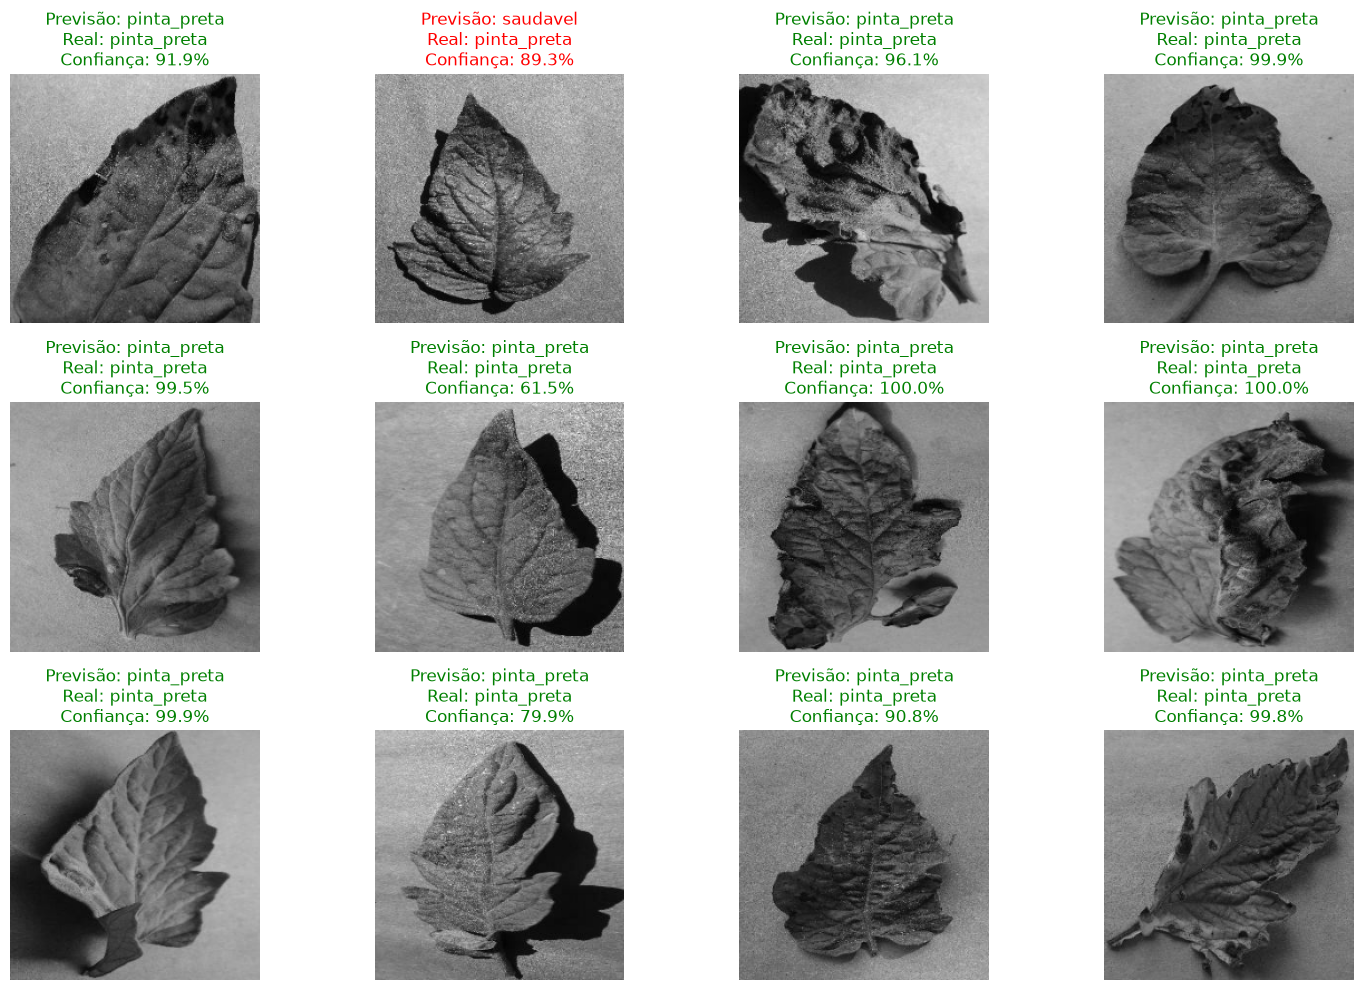

In [13]:
# Puxa o primeiro lote (batch) do conjunto de teste
plt.figure(figsize=(15, 10))
for images, labels in teste_ds.take(1):
    preds = model.predict(images, verbose=0)
    
    for i in range(12): # Vamos olhar 12 folhas
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        
        classe_real = classes[int(labels[i])]
        classe_prevista = classes[int(preds[i] > 0.5)]
        confianca = preds[i][0] if classe_prevista == classes[1] else 1 - preds[i][0]
        
        cor_titulo = "green" if classe_real == classe_prevista else "red"
        
        plt.title(f"Previsão: {classe_prevista}\nReal: {classe_real}\nConfiança: {confianca*100:.1f}%", color=cor_titulo)
        plt.axis("off")
plt.tight_layout()
plt.show()

Encontradas 14 imagens para teste. Iniciando diagnósticos...



c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


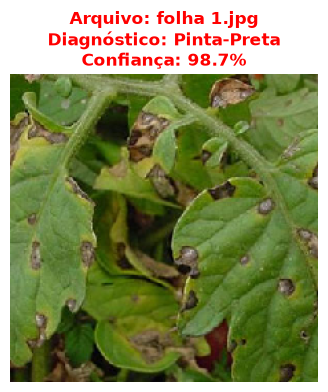

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


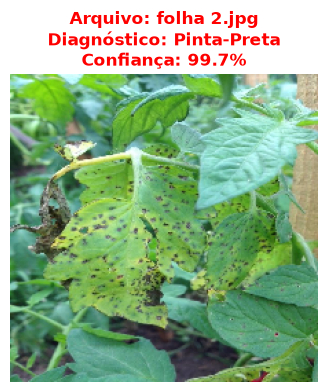

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


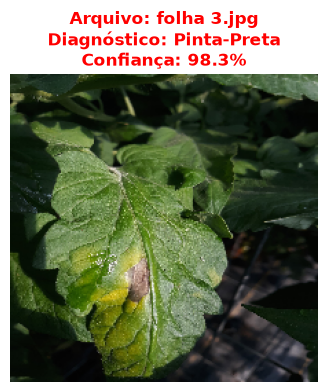

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


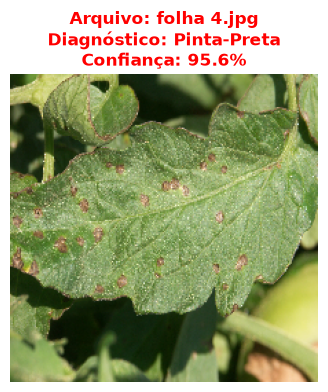

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


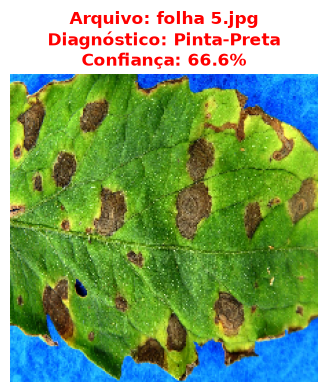

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


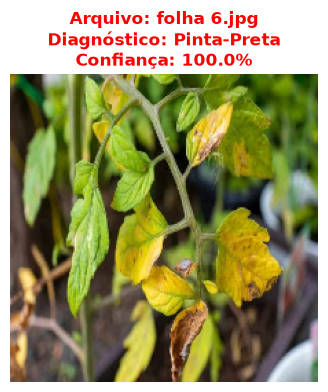

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


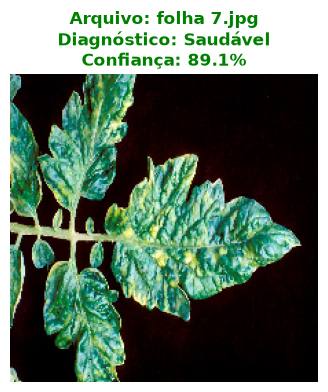

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


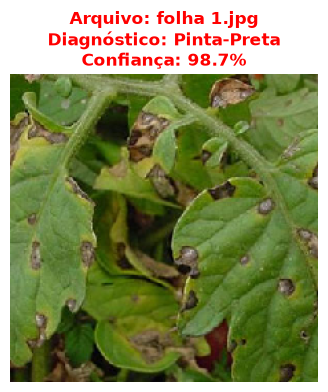

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


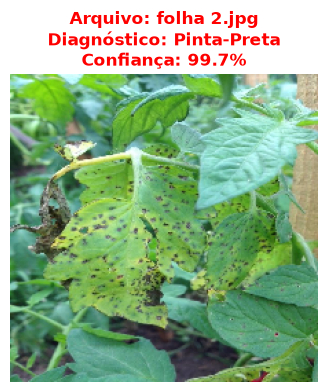

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


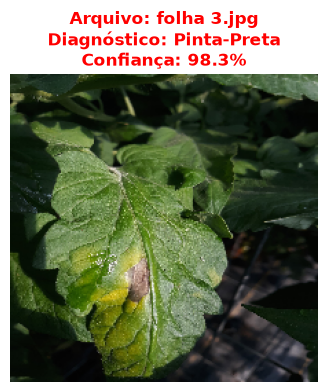

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


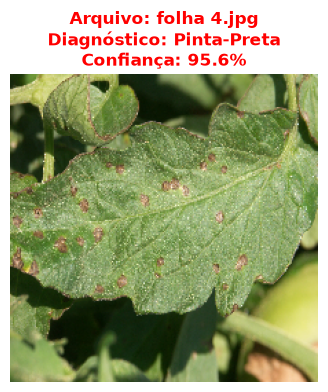

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


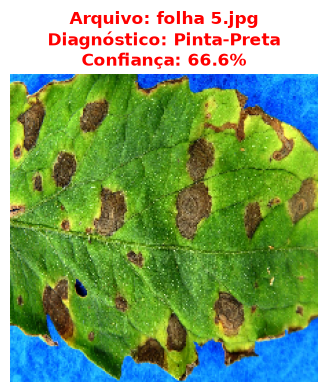

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


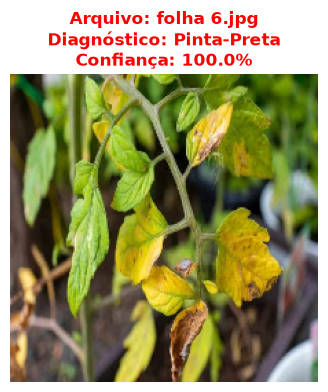

c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\utils\python_utils.py:190: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  value = float(value)


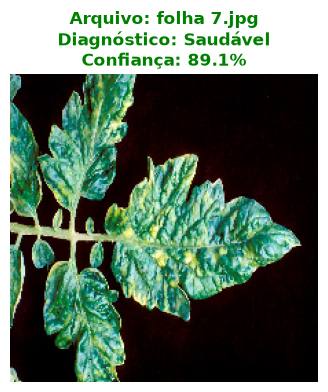

In [18]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

def testar_imagens_da_pasta(diretorio, modelo):
    # Procura por todas as imagens (jpg, jpeg, png) na sua pasta
    extensoes = ('*.jpg', '*.jpeg', '*.png')
    arquivos_imagens = []
    
    for ext in extensoes:
        arquivos_imagens.extend(glob.glob(os.path.join(diretorio, ext)))
        # Tenta achar também com letras maiúsculas (ex: .JPG)
        arquivos_imagens.extend(glob.glob(os.path.join(diretorio, ext.upper())))
        
    if not arquivos_imagens:
        print(f"Nenhuma imagem encontrada na pasta:\n{diretorio}\nSalve algumas fotos lá e rode novamente!")
        return

    print(f"Encontradas {len(arquivos_imagens)} imagens para teste. Iniciando diagnósticos...\n")

    for caminho_imagem in arquivos_imagens:
        try:
            # 1. Carregar a imagem
            img = image.load_img(caminho_imagem, target_size=(224, 224))
            img_array = image.img_to_array(img)
            img_array = np.expand_dims(img_array, axis=0)
            
            # 2. Fazer a previsão
            previsao = modelo.predict(img_array, verbose=0)
            probabilidade = previsao[0][0]
            
            # 3. Interpretar o resultado
            if probabilidade > 0.5:
                classe = "Saudável"
                confianca = probabilidade * 100
                cor = "green"
            else:
                classe = "Pinta-Preta"
                confianca = (1 - probabilidade) * 100
                cor = "red"
                
            # 4. Plotar o resultado
            plt.figure(figsize=(4, 4))
            plt.imshow(img)
            nome_arquivo = os.path.basename(caminho_imagem)
            plt.title(f"Arquivo: {nome_arquivo}\nDiagnóstico: {classe}\nConfiança: {confianca:.1f}%", 
                      color=cor, fontweight='bold')
            plt.axis("off")
            plt.show()
            
        except Exception as e:
            print(f"Erro ao processar a imagem {caminho_imagem}: {e}")

# ==========================================
# EXECUÇÃO DO TESTE
# ==========================================
DIRETORIO_TESTE = r"C:\Users\joaom\OneDrive\Documentos\GitHub\Ecovision\ml\images_test"

# Chama a função passando a sua pasta e o modelo treinado
testar_imagens_da_pasta(DIRETORIO_TESTE, model)